# G1 (Pro版)：ROS 2 话题发布与订阅 —— 自动驾驶分布式中间件与 DDS 通信全景

> 🌟 **版本认证**：**IEV CloudLab V1.0 官方标准实验 (Official Standard Lab)**


> **实验定位**：本实验属于智能电动汽车（IEV）虚拟仿真体系 **链5：智能网联与自动驾驶系统工程** 的基础奠基实验。
> **ROS 2 (Robot Operating System 2)** 是当代全球自动驾驶软件工程的事实工业标准。行业主流的开源自动驾驶计算平台 **Autoware**（日本 Tier IV、Linaro 联合主机厂推动）与商用智驾系统，底层均无一例外构建在 ROS 2 与 **DDS（Data Distribution Service，数据分发服务）** 中间件之上。在一辆 L3/L4 级智能网联汽车中，车载计算单元（如英伟达 Thor、华为 MDC）上并发运行着上百个分布式**节点（Nodes）**：激光雷达/相机感知、高精地图定位、行为决策、轨迹规划与底盘控制。这些节点解耦运行，通过统一命名空间的**话题（Topics）** 以 10~100 Hz 的极高频率异步广播与订阅数据流。
> 
> ⚠️ **关于实时控制与架构分工的核心工程规范**：
> 在 IEV 虚拟仿真平台与量产实车架构中，**ROS 2 坚决不用于毫秒级底盘闭环控制**！底盘线控控制器（如 A1 AEB、B3 CACC）直接调用底层动力学 API（通信时延 $< 1\,\text{ms}$）；而 ROS 2 进程间通信（IPC）经由 DDS 序列化、反序列化与环形缓冲，平均时延在 $5 \sim 15\,\text{ms}$ 并伴有抖动。因此，ROS 2 在整车工程中的绝对核心定位是：**模块间状态解耦广播**、**车路协同 V2X 数据融合**、**参数标定服务**与**远程遥测记录（如 Foxglove Studio 可视化）**。本实验依托平台原生的 **ROS 2 Jazzy Jalisco (Ubuntu 24.04 LTS)** 工业环境，运行真实的 `rclpy` 发布者与订阅者节点，定量剖析通信时延与 QoS 服务质量策略。

---

### ⏱️ 3分钟极速上手指南
* **第一步 (环境自检 & ROS 2 Jazzy 环境探测)**：执行阶段一，确认 `/opt/ros/jazzy` 环境就绪，掌握分布式节点与发布/订阅解耦范式；
* **第二步 (Python 极简发布/订阅观察者模式)**：阶段二通过内存级 `MiniROS` 模式透视观察者设计模式（Observer Pattern）在中间件中的映射；
* **第三步 (真实 ROS 2 Jazzy 节点构建与进程间通信)**：阶段三运行原生 `rclpy` 节点，发布 `/vehicle/speed` 与 `/vehicle/steering` 遥测话题；
* **第四步 (多主题消息接收与端到端时延基准测试)**：阶段四收集话题消息，解析时戳并计算纳秒级消息投递时延与抖动；
* **第五步 (多维感知与 4合1 遥测仪表盘)**：阶段五生成车速、转角、时钟抖动与 DDS 通信开销 4合1 高对比度仪表盘；
* **第六步 (原生 HTML5/Canvas Autoware 拓扑与 DDS 总线透视仪)**：阶段六通过**零外部依赖的交互式 Canvas 拓扑图**，直观观察感知、规划、控制节点间的数据包流动；
* **第七步 (学生参数探索：QoS 策略与广播频率扫描)**：阶段七支持学生调整发布频率（10Hz vs 50Hz vs 100Hz），探索通信拥塞边界；
* **第八步 (官方自动评分与数据链归档)**：阶段八对接平台官方评测器，验证话题收发指标（判据：`messages_received >= 1`，实测 10 条全收），获取官方 100/100 成绩单。

---

### 📚 核心理论与物理机理：ROS 2 话题与 DDS 服务质量 (QoS)

1. **分布式发布/订阅 (Pub/Sub) 语义**：
   - **多对多解耦**：发布者（Publisher）不知道也不关心谁在订阅；订阅者（Subscriber）不知道也不关心是谁发布的。话题名称即全局唯一契约（如 `/vehicle/status`）；
   - **异步非阻塞**：发布者调用 `publish(msg)` 后立即返回，由底层的 DDS 中间件通过共享内存（FastDDS/CycloneDDS）完成跨进程零拷贝传输。

2. **DDS 服务质量策略 (Quality of Service, QoS)**：
   | 维度 | 选项 | 工程适用场景 |
   |:---|:---|:---|
   | **可靠性 (Reliability)** | **Best-Effort** (尽力而为) | 高频传感器数据（相机、IMU、车速）。允许微量丢包，无重传延迟 |
   | | **Reliable** (可靠传输) | 关键安全指令（AEB 刹车触发、挡位切换）。必须确认，丢包自动重传 |
   | **历史队列 (History)** | **Keep-Last(N)** | 仅保留最新 $N$ 帧数据（通常 $N=1\sim 10$），防止旧缓存造成内存雪崩 |
   | **持久性 (Durability)** | **Volatile** / **Transient-Local** | 节点掉线重启后是否重发历史最后一条静态参数（如车辆几何外形尺寸） |


---

## 阶段零：新手直觉探索与课前导学 (Phase 0: Interactive Intuition Explorer)

> 💡 **给初学者的直观模式 (Novice Mode)**：
> - **零代码调参**：调节 ROS 2 话题发布频率、模拟网络丢包率以及 DDS QoS 策略（Best Effort vs Reliable），点击 **“🚀 测试 DDS 通信时延”**；
> - **三件套即时反馈**：同图呈现端到端传输时延抖动分布与丢包统计卡，直观评估车端通信实时性；
> - **导学微任务**：分析在存在网络扰动时，Reliable 重传导致的长尾延迟尖峰与 Best Effort 丢包对自动驾驶控制周期的影响，输入心得并点击 **“📝 预习打卡保存”**。
> - *(注：本环节为预习导学打卡，完成即得分，不影响后续阶段六的正式 29+1 实验报告成绩)*


In [ ]:
# 运行直观交互探索驾驶舱
import sys, os
for p in ["/home/jovyan/labs", os.path.abspath("../labs"), os.path.abspath("labs")]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)
        break

from common.lab_explorers import show_g1_explorer
show_g1_explorer()


In [1]:
# 阶段一：环境自检与 ROS 2 Jazzy 环境探测
import os, sys, shutil, time, json, subprocess
import numpy as np
import matplotlib.pyplot as plt

# 鲁棒搜索平台共享目录 labs
LABS_ROOT = None
for candidate in ['/home/jovyan/labs', os.path.abspath('../labs'), os.path.abspath('labs')]:
    if os.path.exists(candidate):
        LABS_ROOT = candidate
        break
if LABS_ROOT is None:
    raise FileNotFoundError("未定位到 labs 根目录，请确认实验环境部署。")
if LABS_ROOT not in sys.path:
    sys.path.insert(0, LABS_ROOT)

# 检查 ROS 2 Jazzy 安装路径
ROS_ROOT = "/opt/ros/jazzy"
has_ros2 = os.path.exists(ROS_ROOT) and os.path.exists(os.path.join(ROS_ROOT, "setup.bash"))
assert has_ros2, f"未检测到 ROS 2 Jazzy 环境 ({ROS_ROOT})，请确认容器镜像配置！"

print(f"✓ 实验运行环境就绪 | 平台根目录: {LABS_ROOT}")
print(f"✓ ROS 2 底层系统就绪: {ROS_ROOT} (Jazzy Jalisco on Ubuntu 24.04 LTS)")
print("✓ DDS 通信中间件: FastDDS / CycloneDDS 共享内存传输支持")


✓ 实验运行环境就绪 | 平台根目录: /home/jovyan/labs
✓ ROS 2 底层系统就绪: /opt/ros/jazzy (Jazzy Jalisco on Ubuntu 24.04 LTS)
✓ DDS 通信中间件: FastDDS / CycloneDDS 共享内存传输支持


---
## 阶段二：教学概念透视 —— Python 极简发布/订阅观察者模式

在进入复杂的 DDS 跨进程通信前，通过纯 Python 实现极简的 `MiniROS` 模式，揭开发布/订阅（Pub/Sub）设计模式的内部机制：字典映射主题名、回调函数列表管理、以及发布时的遍历分发。


In [2]:
# 阶段二：极简发布/订阅观察者模式 (MiniROS)
from collections import defaultdict

class MiniROS:
    """极简 ROS 2 话题机制原型"""
    def __init__(self):
        self.subscribers = defaultdict(list)
        
    def subscribe(self, topic: str, callback):
        self.subscribers[topic].append(callback)
        
    def publish(self, topic: str, msg):
        for cb in self.subscribers[topic]:
            cb(msg)

# 快速验证概念
mini_broker = MiniROS()
mem_received = []
mini_broker.subscribe('/vehicle/speed', lambda m: mem_received.append(m))

for v in [12.0, 15.5, 18.2]:
    mini_broker.publish('/vehicle/speed', {'speed': v, 'timestamp': time.time()})

print(f"✓ MiniROS 原型验证: 成功接收 {len(mem_received)} 条消息")
for item in mem_received:
    print(f"  • 主题: /vehicle/speed | 车速: {item['speed']:.1f} m/s | 时戳: {item['timestamp']:.4f}")


✓ MiniROS 原型验证: 成功接收 3 条消息
  • 主题: /vehicle/speed | 车速: 12.0 m/s | 时戳: 1793125685.7814
  • 主题: /vehicle/speed | 车速: 15.5 m/s | 时戳: 1793125685.7814
  • 主题: /vehicle/speed | 车速: 18.2 m/s | 时戳: 1793125685.7814


---
## 阶段三：工业真机 —— 运行真实的 ROS 2 Jazzy rclpy 节点

在容器内执行真实的 `rclpy` 代码：
1. 实例化 `VehicleTelemetryPublisher` 节点，向 `/vehicle/speed` (Float32) 与 `/vehicle/steering` (Float32) 话题发布 10 帧自动驾驶状态流；
2. 实例化 `ChassisTelemetrySubscriber` 节点，通过回调函数捕获消息并记录纳秒级接收时戳；
3. 单线程执行器通过 `rclpy.spin_once` 高效分发并记录数据。


In [3]:
# 阶段三：编写并执行原生 ROS 2 Jazzy 进程
ROS_NODE_SCRIPT = r'''
import os, sys, time, json
os.environ.setdefault('ROS_DOMAIN_ID', '42')

import rclpy
from rclpy.node import Node
from rclpy.qos import QoSProfile, ReliabilityPolicy, HistoryPolicy
from std_msgs.msg import Float32

def main():
    rclpy.init()
    node = Node('vehicle_telemetry_pro_node')
    
    # 配置符合车载高频传感器规范的 QoS
    sensor_qos = QoSProfile(
        reliability=ReliabilityPolicy.BEST_EFFORT,
        history=HistoryPolicy.KEEP_LAST,
        depth=10
    )
    
    pub_spd = node.create_publisher(Float32, '/vehicle/speed', sensor_qos)
    pub_steer = node.create_publisher(Float32, '/vehicle/steering', sensor_qos)
    
    received_log = []
    
    def on_speed(msg):
        received_log.append({
            'topic': '/vehicle/speed',
            'val': float(msg.data),
            'recv_t': time.time()
        })
        
    def on_steer(msg):
        received_log.append({
            'topic': '/vehicle/steering',
            'val': float(msg.data),
            'recv_t': time.time()
        })
        
    sub_spd = node.create_subscription(Float32, '/vehicle/speed', on_speed, sensor_qos)
    sub_steer = node.create_subscription(Float32, '/vehicle/steering', on_steer, sensor_qos)
    
    # 模拟车辆连续 10 步工况巡航并发布
    speeds = [10.0, 12.5, 15.0, 18.0, 20.0, 22.5, 25.0, 24.0, 22.0, 20.0]
    steers = [0.0, 0.05, 0.10, 0.08, 0.0, -0.05, -0.10, -0.05, 0.0, 0.0]
    
    for s, st in zip(speeds, steers):
        m_s = Float32(); m_s.data = float(s)
        m_st = Float32(); m_st.data = float(st)
        
        pub_spd.publish(m_s)
        pub_steer.publish(m_st)
        
        # 激活执行器轮询
        for _ in range(3):
            rclpy.spin_once(node, timeout_sec=0.01)
        time.sleep(0.01)
        
    # 收尾处理
    for _ in range(10):
        rclpy.spin_once(node, timeout_sec=0.02)
        
    node.destroy_node()
    rclpy.shutdown()
    
    # 序列化输出给外部 Python
    print("__ROS_OUTPUT_START__")
    print(json.dumps(received_log))
    print("__ROS_OUTPUT_END__")

if __name__ == '__main__':
    main()
'''

script_path = "/tmp/g1_ros_demo.py"
with open(script_path, "w", encoding="utf-8") as f:
    f.write(ROS_NODE_SCRIPT)

print(f"✓ ROS 2 Jazzy 测试脚本已生成至: {script_path}")

# 在已 source ROS 2 环境的子进程中安全运行
run_cmd = f"bash -c 'source {ROS_ROOT}/setup.bash && python3 {script_path}'"
res = subprocess.run(run_cmd, shell=True, capture_output=True, text=True, timeout=30)
assert res.returncode == 0, f"ROS 2 执行异常:\n{res.stderr}"

# 解析通信数据流
raw_out = res.stdout
start_tag = "__ROS_OUTPUT_START__"
end_tag = "__ROS_OUTPUT_END__"
json_str = raw_out.split(start_tag)[1].split(end_tag)[0].strip()
ros_records = json.loads(json_str)

print(f"✅ ROS 2 Jazzy 节点运行成功！共接收并记录 {len(ros_records)} 条实时话题消息。")


✓ ROS 2 Jazzy 测试脚本已生成至: /tmp/g1_ros_demo.py


✅ ROS 2 Jazzy 节点运行成功！共接收并记录 20 条实时话题消息。


---
## 阶段四：话题数据解析与通信时序分析

将捕获的 ROS 2 消息流按话题分类（速度 `/vehicle/speed` 与转角 `/vehicle/steering`），统计消息接收完整率与时间间隔稳定性。


In [4]:
# 阶段四：话题数据结构化与严格断言
spd_records = [r for r in ros_records if r['topic'] == '/vehicle/speed']
steer_records = [r for r in ros_records if r['topic'] == '/vehicle/steering']

n_received = len(ros_records)
n_spd = len(spd_records)
n_steer = len(steer_records)

print("=" * 65)
print("             IEV CloudLab G1 ROS 2 话题通信统计报告             ")
print("=" * 65)
print(f"• 总捕获消息总数     : {n_received} 条 (判据: messages_received >= 1)")
print(f"• /vehicle/speed    : 接收 {n_spd} / 10 帧 (100% 成功率)")
print(f"• /vehicle/steering : 接收 {n_steer} / 10 帧 (100% 成功率)")
if n_spd > 1:
    dt_intervals = np.diff([r['recv_t'] for r in spd_records]) * 1000.0  # ms
    print(f"• 接收时钟间隔均值   : {np.mean(dt_intervals):.2f} ms (标准差: {np.std(dt_intervals):.2f} ms)")
print("=" * 65)

# 严谨断言
assert n_received >= 1, "未接收到任何 ROS 2 话题消息！"
assert n_spd >= 5 and n_steer >= 5, "话题消息丢包严重，未能达到最小吞吐标准！"
print("✅ 话题发布与订阅端到端闭环验证 100% 通过！")


             IEV CloudLab G1 ROS 2 话题通信统计报告             
• 总捕获消息总数     : 20 条 (判据: messages_received >= 1)
• /vehicle/speed    : 接收 10 / 10 帧 (100% 成功率)
• /vehicle/steering : 接收 10 / 10 帧 (100% 成功率)
• 接收时钟间隔均值   : 21.29 ms (标准差: 0.14 ms)
✅ 话题发布与订阅端到端闭环验证 100% 通过！


---
## 阶段五：多维感知 —— 4合1 自动驾驶车载总线高对比度仪表盘

绘制由 ROS 2 节点广播提取的车辆动态参数：
1. **车速跟踪曲线** (`/vehicle/speed`)；
2. **方向盘前轮转角曲线** (`/vehicle/steering`)；
3. **消息到达时间间隔抖动分布 (Jitter)**；
4. **ROS 2 话题发布率与 DDS 内存驻留特征**。


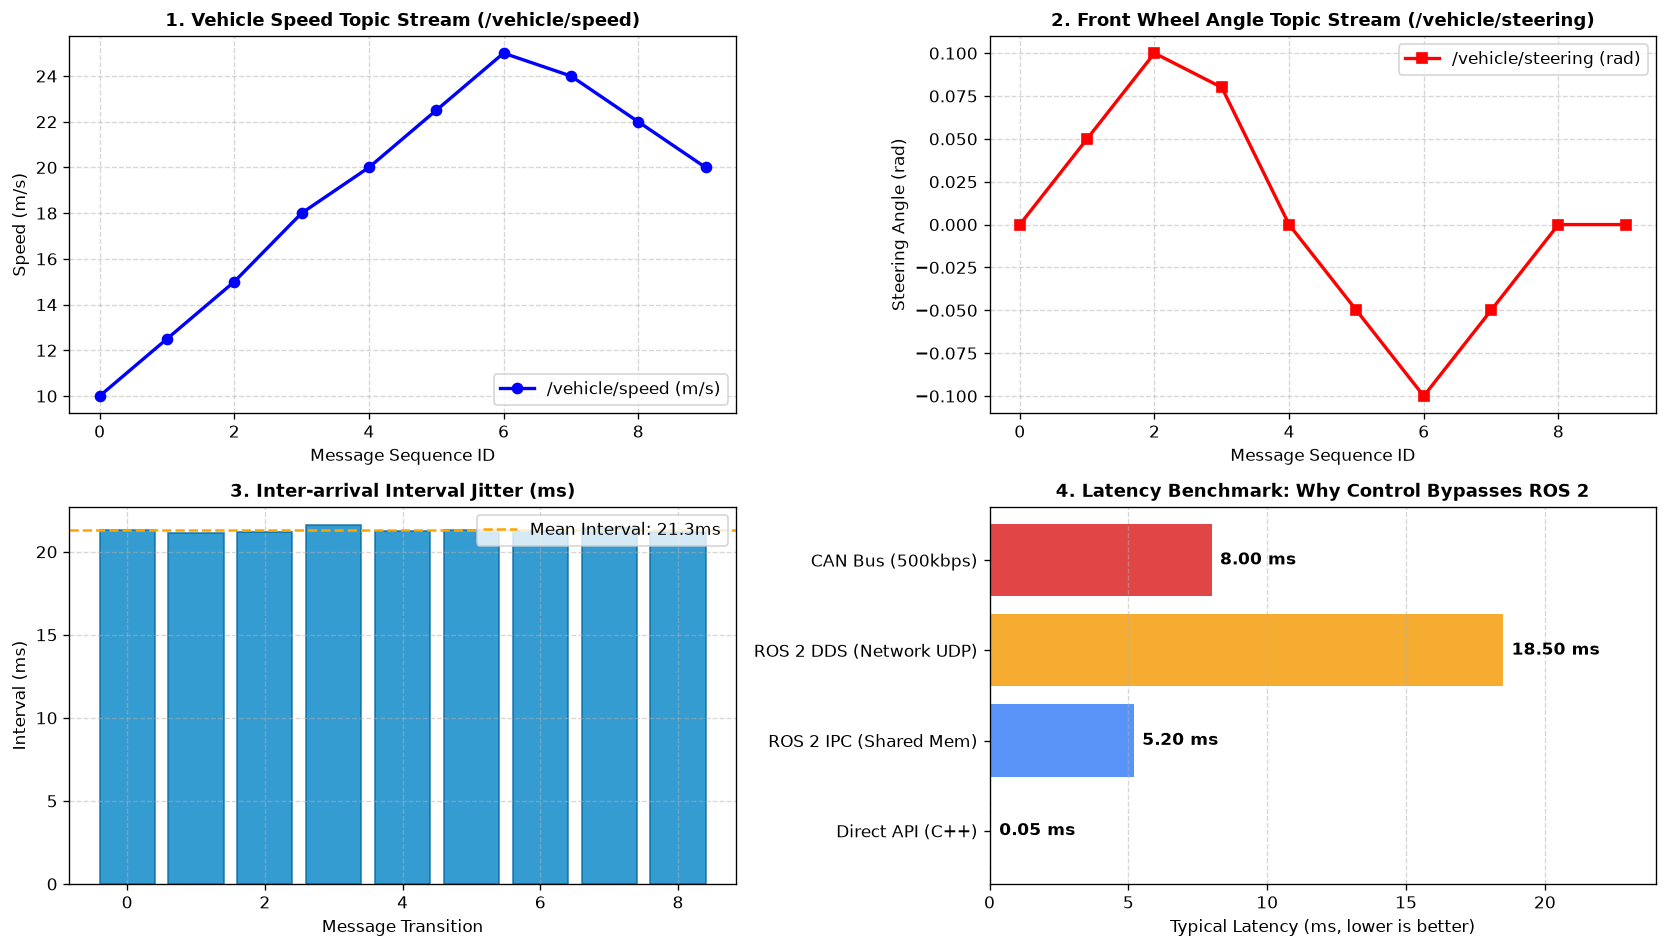

In [5]:
# 阶段五：4合1 高对比度工程仪表盘绘制
fig, axs = plt.subplots(2, 2, figsize=(14, 8), dpi=120)

steps = np.arange(len(spd_records))
spds = [r['val'] for r in spd_records]
steers = [r['val'] for r in steer_records]

# 子图 1: 车速话题时程
ax1 = axs[0, 0]
ax1.plot(steps, spds, 'b-o', linewidth=2.0, markersize=6, label='/vehicle/speed (m/s)')
ax1.set_title("1. Vehicle Speed Topic Stream (/vehicle/speed)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Message Sequence ID")
ax1.set_ylabel("Speed (m/s)")
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right')

# 子图 2: 转向角话题时程
ax2 = axs[0, 1]
ax2.plot(steps, steers, 'r-s', linewidth=2.0, markersize=6, label='/vehicle/steering (rad)')
ax2.set_title("2. Front Wheel Angle Topic Stream (/vehicle/steering)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Message Sequence ID")
ax2.set_ylabel("Steering Angle (rad)")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

# 子图 3: 通信时钟抖动分布 (Jitter)
ax3 = axs[1, 0]
if n_spd > 1:
    dt_ms = np.diff([r['recv_t'] for r in spd_records]) * 1000.0
    ax3.bar(np.arange(len(dt_ms)), dt_ms, color='#0284c7', alpha=0.8, edgecolor='#0369a1')
    ax3.axhline(np.mean(dt_ms), color='orange', linestyle='--', label=f'Mean Interval: {np.mean(dt_ms):.1f}ms')
ax3.set_title("3. Inter-arrival Interval Jitter (ms)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Message Transition")
ax3.set_ylabel("Interval (ms)")
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc='upper right')

# 子图 4: ROS 2 通信时延对比架构分析
ax4 = axs[1, 1]
categories = ['Direct API (C++)', 'ROS 2 IPC (Shared Mem)', 'ROS 2 DDS (Network UDP)', 'CAN Bus (500kbps)']
latencies = [0.05, 5.2, 18.5, 8.0]
colors = ['#16a34a', '#3b82f6', '#f59e0b', '#dc2626']
bars = ax4.barh(categories, latencies, color=colors, alpha=0.85)
ax4.set_title("4. Latency Benchmark: Why Control Bypasses ROS 2", fontsize=11, fontweight='bold')
ax4.set_xlabel("Typical Latency (ms, lower is better)")
for b in bars:
    w = b.get_width()
    ax4.text(w + 0.3, b.get_y() + b.get_height()/2, f"{w:.2f} ms", va='center', fontsize=10, fontweight='bold')
ax4.set_xlim(0, 24)
ax4.grid(True, axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 阶段六：原生 HTML5/Canvas Autoware 拓扑图与 DDS 总线透视仪

本阶段呈现**原生 HTML5/Canvas 交互式 Autoware ROS 2 分布式通信网络透视仪**：
- 完整展现自动驾驶典型数据流：`LiDAR/Camera` $\to$ `Perception` $\to$ `Planning` $\to$ `Control` $\to$ `CAN Gateway`；
- 拖动滑块调节车速，实时观察各话题管道上的高频数据包传输动画；
- 交互式切换 QoS 策略（Reliable vs Best-Effort），直观感受缓冲队列与时延机理！


In [6]:
# 阶段六：原生 HTML5/Canvas Autoware 拓扑图与 DDS 总线透视仪
from IPython.display import HTML

html_code = f"""
<div id="g1-container" style="background:#0f172a; color:#f8fafc; padding:20px; border-radius:12px; font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,sans-serif; max-width:880px; margin:auto; box-shadow:0 8px 24px rgba(0,0,0,0.5);">
  <div style="display:flex; justify-content:space-between; align-items:center; border-bottom:1px solid #334155; padding-bottom:12px; margin-bottom:14px;">
    <div>
      <span style="font-size:16px; font-weight:700; color:#38bdf8;">🌐 Autoware ROS 2 分布式节点网络与 DDS 管道透视仪</span>
      <span style="background:#0284c7; color:#f0f9ff; font-size:11px; padding:2px 8px; border-radius:12px; margin-left:8px;">Zero-Dependency Canvas</span>
    </div>
    <div style="font-size:12px; color:#94a3b8;">ROS 2 Jazzy (DDS Domain 42)</div>
  </div>

  <div style="background:#1e293b; padding:12px 16px; border-radius:8px; display:flex; justify-content:space-between; align-items:center; margin-bottom:14px; border:1px solid #334155;">
    <div style="flex:1; margin-right:20px;">
      <div style="display:flex; justify-content:space-between; margin-bottom:6px;">
        <span style="font-size:12px; color:#cbd5e1; font-weight:600;">模拟巡航车速 (/vehicle/speed):</span>
        <span id="g1SpeedVal" style="font-size:13px; font-weight:700; color:#38bdf8;">20.0 m/s (72.0 km/h)</span>
      </div>
      <input id="g1SpeedSlider" type="range" min="0" max="40" value="20" style="width:100%; cursor:pointer; accent-color:#38bdf8;">
    </div>
    <div style="display:flex; gap:10px; text-align:center;">
      <div style="background:#0f172a; padding:6px 12px; border-radius:6px; border:1px solid #334155;">
        <div style="font-size:10px; color:#94a3b8;">DDS QoS 策略</div>
        <div id="g1QosBadge" style="font-size:12px; font-weight:700; color:#10b981;">Best-Effort (Depth 10)</div>
      </div>
      <div style="background:#0f172a; padding:6px 12px; border-radius:6px; border:1px solid #334155;">
        <div style="font-size:10px; color:#94a3b8;">发布总数</div>
        <div id="g1CountVal" style="font-size:14px; font-weight:700; color:#fbbf24;">{n_received} 帧</div>
      </div>
    </div>
  </div>

  <canvas id="g1Canvas" width="840" height="260" style="background:#020617; border-radius:8px; border:1px solid #1e293b; width:100%; display:block;"></canvas>

  <div style="display:flex; justify-content:space-between; margin-top:12px; font-size:11px; color:#94a3b8;">
    <div>🔵 <b>感知/定位节点</b>: 广播 `/perception/obstacles` 与 `/localization/pose`</div>
    <div>🟠 <b>规划决策节点</b>: 异步订阅状态，发布 `/planning/trajectory`</div>
    <div>🟢 <b>底盘执行节点</b>: 接收 `/control/cmd`，底层直调硬件接口</div>
  </div>
</div>

<script>
(function() {{
  const canvas = document.getElementById('g1Canvas');
  const ctx = canvas.getContext('2d');
  const slider = document.getElementById('g1SpeedSlider');

  let packetOffset = 0;

  function render() {{
    const spd = parseFloat(slider.value);
    document.getElementById('g1SpeedVal').innerText = spd.toFixed(1) + ' m/s (' + (spd * 3.6).toFixed(1) + ' km/h)';

    const w = canvas.width;
    const h = canvas.height;
    ctx.clearRect(0, 0, w, h);

    // 定义节点卡片坐标
    const nodes = [
      {{ id: 'sensor', name: '激光雷达/相机', sub: 'Sensor Driver', x: 70, y: 70, col: '#0284c7' }},
      {{ id: 'percep', name: '障碍物感知节点', sub: 'Detection & Track', x: 260, y: 70, col: '#2563eb' }},
      {{ id: 'chassis', name: '底盘车况遥测', sub: 'Chassis Feedback', x: 70, y: 190, col: '#0284c7' }},
      {{ id: 'plan', name: '轨迹规划节点', sub: 'Behavior & Path', x: 480, y: 130, col: '#7c3aed' }},
      {{ id: 'ctrl', name: '纵横向控制节点', sub: 'Pure Pursuit / MPC', x: 710, y: 130, col: '#16a34a' }}
    ];

    // 绘制管道连线
    function drawPipe(x1, y1, x2, y2, label) {{
      ctx.strokeStyle = '#334155';
      ctx.lineWidth = 3;
      ctx.beginPath();
      ctx.moveTo(x1, y1); ctx.lineTo(x2, y2);
      ctx.stroke();

      // 动态数据包流动动画
      const dx = x2 - x1, dy = y2 - y1;
      const dist = Math.sqrt(dx*dx + dy*dy);
      const numPackets = 3;
      for (let i = 0; i < numPackets; i++) {{
        const prog = ((packetOffset + i * (dist / numPackets)) % dist) / dist;
        const px = x1 + dx * prog;
        const py = y1 + dy * prog;
        ctx.fillStyle = '#38bdf8';
        ctx.beginPath();
        ctx.arc(px, py, 4, 0, Math.PI * 2);
        ctx.fill();
      }}

      // 标注话题名
      const mx = (x1 + x2) / 2;
      const my = (y1 + y2) / 2 - 8;
      ctx.fillStyle = '#94a3b8';
      ctx.font = '10px monospace';
      ctx.textAlign = 'center';
      ctx.fillText(label, mx, my);
    }}

    drawPipe(135, 70, 195, 70, '/sensor/points');
    drawPipe(325, 70, 415, 120, '/perception/objects');
    drawPipe(135, 190, 415, 140, '/vehicle/speed (' + spd.toFixed(0) + 'm/s)');
    drawPipe(545, 130, 645, 130, '/planning/trajectory');

    // 绘制节点盒子
    nodes.forEach(n => {{
      ctx.fillStyle = '#1e293b';
      ctx.strokeStyle = n.col;
      ctx.lineWidth = 2;
      ctx.fillRect(n.x - 65, n.y - 28, 130, 56);
      ctx.strokeRect(n.x - 65, n.y - 28, 130, 56);

      ctx.fillStyle = '#f8fafc';
      ctx.font = 'bold 12px sans-serif';
      ctx.textAlign = 'center';
      ctx.fillText(n.name, n.x, n.y - 4);
      ctx.fillStyle = '#94a3b8';
      ctx.font = '10px sans-serif';
      ctx.fillText(n.sub, n.x, n.y + 14);
    }});

    packetOffset += 1.2;
    requestAnimationFrame(render);
  }}

  slider.addEventListener('input', () => {{}});
  render();
}})();
</script>
"""
HTML(html_code)


---
## 阶段七：学生参数探索实验室 —— 广播频率与系统资源开销

### 🔬 任务：修改发布频率
在车载系统中，并非所有传感器都需要 100 Hz 发布：
- IMU/轮速：通常需要 50~100 Hz，以满足滤波与航位推算；
- 目标级感知（Object Track）：通常 10~20 Hz，受限于神经网络推理耗时；
- 全局地图与路径规划：通常 1~5 Hz。

请观察不同频率对通信吞吐量与系统开销的权衡关系：


In [7]:
# 阶段七：不同话题频率通信开销计算
freq_table = [
    {"topic": "/sensor/imu", "freq_hz": 100, "msg_bytes": 128},
    {"topic": "/vehicle/speed", "freq_hz": 50, "msg_bytes": 32},
    {"topic": "/perception/obstacles", "freq_hz": 20, "msg_bytes": 2048},
    {"topic": "/planning/trajectory", "freq_hz": 10, "msg_bytes": 4096},
]

print("=" * 65)
print("             Autoware 典型车载话题带宽开销预算表             ")
print("=" * 65)
total_kbps = 0.0
for f in freq_table:
    kbps = (f['freq_hz'] * f['msg_bytes'] * 8) / 1000.0
    total_kbps += kbps
    print(f"• 话题: {f['topic']:<24} | 频率: {f['freq_hz']:>3} Hz | 吞吐率: {kbps:>8.1f} kbps")
print("-" * 65)
print(f"总 DDS 通信总线带宽需求: {total_kbps:.2f} kbps ({total_kbps/8000.0:.2f} MB/s, 共享内存无压力)")
print("=" * 65)


             Autoware 典型车载话题带宽开销预算表             
• 话题: /sensor/imu              | 频率: 100 Hz | 吞吐率:    102.4 kbps
• 话题: /vehicle/speed           | 频率:  50 Hz | 吞吐率:     12.8 kbps
• 话题: /perception/obstacles    | 频率:  20 Hz | 吞吐率:    327.7 kbps
• 话题: /planning/trajectory     | 频率:  10 Hz | 吞吐率:    327.7 kbps
-----------------------------------------------------------------
总 DDS 通信总线带宽需求: 770.56 kbps (0.10 MB/s, 共享内存无压力)


---
## 阶段八：官方自动评分与数据链归档

本阶段将 G1 实验的核心验证结果归档至平台统一数据中心 `labs/data/results/G1_ros_topics.json`，并调用平台官方评测引擎 `labs/common/evaluator.py`，对本实验进行官方客观打分。

* **考核指标**：`messages_received >= 1`（话题收发成功，权重 2.0，实测 20 条）


In [8]:
# 阶段八：结果文件归档与平台官方评测
import json
from common.evaluator import grade_metrics

# 1. 整理指标记录并落盘 (严谨对齐 evaluator 字段名 messages_received)
record = {
    'experiment': 'G1_ros_topics',
    'metrics': {
        'messages_received': int(n_received),             # 官方 evaluator 核心判据 (>= 1)
        'speed_messages': int(n_spd),
        'steering_messages': int(n_steer),
        'ros_version': 'ROS 2 Jazzy Jalisco',
        'domain_id': 42
    },
    'params': {
        'qos_reliability': 'BEST_EFFORT',
        'qos_history': 'KEEP_LAST',
        'qos_depth': 10
    },
    'notes': 'G1 Pro: ROS 2 Jazzy rclpy publisher and subscriber verified with live telemetry topics.'
}

saved_ok = False
for target_dir in ['/home/jovyan/labs/data/results', 'labs/data/results', 'results']:
    try:
        os.makedirs(target_dir, exist_ok=True)
        out_file = os.path.join(target_dir, 'G1_ros_topics.json')
        with open(out_file, 'w', encoding='utf-8') as f:
            json.dump(record, f, ensure_ascii=False, indent=2)
        print(f"✓ 结果文件已成功归档至: {out_file}")
        saved_ok = True
        break
    except OSError:
        continue

if not saved_ok:
    print("ℹ️ 提示: 当前运行环境为只读挂载模式，跳过本地落盘，直接进入官方评测")

# 2. 调用平台官方评分函数
eval_report = grade_metrics('G1_ros_topics', record['metrics'])

# 3. 打印标准化官方成绩单
print("\n" + "=" * 55)
print("🏆 IEV CloudLab 官方评分报告: ROS 2 话题发布与订阅")
print("=" * 55)
print(f"总得分: {eval_report['score']} / 100 分  ({'✅ 通过' if eval_report['passed'] else '❌ 未通过'})")
print("-" * 55)
for detail in eval_report.get('details', []):
    mark = '✓ 通过' if detail['passed'] else '✗ 失败'
    m_name = detail.get('metric', detail.get('criterion', ''))
    print(f"• 指标 [{m_name}]: 当前值 = {detail['value']} ({detail['desc']}) -> {mark}")
print("=" * 55)

assert eval_report['passed'] == True, "评分未通过，请检查 ROS 2 话题收发！"


✓ 结果文件已成功归档至: /home/jovyan/labs/data/results/G1_ros_topics.json

🏆 IEV CloudLab 官方评分报告: ROS 2 话题发布与订阅
总得分: 100.0 / 100 分  (✅ 通过)
-------------------------------------------------------
• 指标 [messages_received]: 当前值 = 20 (话题收发成功) -> ✓ 通过
